In [2]:
import torch
import torch.nn as nn
import torch.optim as optim

import mlflow
import mlflow.pytorch

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("PyTorch:", torch.__version__)
print("MLflow:", mlflow.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch: 2.5.1+cu121
MLflow: 2.19.0
CUDA available: True


In [3]:
import sys
from pathlib import Path

PROJECT_ROOT = Path(
    r"C:\cs\Projects\cv-projects\Brain_tumor"
)

sys.path.append(str(PROJECT_ROOT / "src"))

from data import (
    create_dataloaders,
    CLASS_NAMES,
    DEVICE
)

train_loader, val_loader, test_loader = create_dataloaders()

print("Device:", DEVICE)
print("Classes:", CLASS_NAMES)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Device: cuda
Classes: ['normal', 'glioma_tumor', 'meningioma_tumor', 'pituitary_tumor']
Training batches: 125
Validation batches: 27
Testing batches: 27


In [4]:
import sys

sys.path.append(str(PROJECT_ROOT / "src"))

from model import BrainTumorCNN

model = BrainTumorCNN(num_classes=4).to(DEVICE)

sample_images, sample_labels = next(iter(train_loader))

sample_images = sample_images.to(DEVICE)

outputs = model(sample_images)

print("Input shape:", sample_images.shape)
print("Output shape:", outputs.shape)
print("Device:", next(model.parameters()).device)

Input shape: torch.Size([16, 3, 256, 256])
Output shape: torch.Size([16, 4])
Device: cuda:0


In [5]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

EPOCHS = 20

print("Loss:", criterion)
print("Optimizer:", optimizer)
print("Epochs:", EPOCHS)

Loss: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Epochs: 20


In [6]:
# MLflow configuration

mlflow.set_tracking_uri(
    (PROJECT_ROOT / "mlruns").as_uri()
)

mlflow.set_experiment("Brain_Tumor_Classification")

print("Tracking URI:", mlflow.get_tracking_uri())
print("Experiment:", mlflow.get_experiment_by_name(
    "Brain_Tumor_Classification"
).name)

2026/11/11 18:49:37 INFO mlflow.tracking.fluent: Experiment with name 'Brain_Tumor_Classification' does not exist. Creating a new experiment.


Tracking URI: file:///C:/cs/Projects/cv-projects/Brain_tumor/mlruns
Experiment: Brain_Tumor_Classification


In [8]:
from data import create_dataloaders, CLASS_NAMES, DEVICE, BATCH_SIZE

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

best_val_loss = float("inf")

with mlflow.start_run():

    # Log hyperparameters
    mlflow.log_params({
        "architecture": "BrainTumorCNN",
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "learning_rate": 0.001,
        "optimizer": "Adam",
        "loss": "CrossEntropyLoss"
    })

    for epoch in range(EPOCHS):

        # Training
        model.train()

        train_loss = 0.0
        train_correct = 0
        train_total = 0

        for images, labels in train_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            train_correct += (predictions == labels).sum().item()
            train_total += labels.size(0)

        train_loss /= train_total
        train_accuracy = train_correct / train_total

        # Validation
        model.eval()

        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images = images.to(DEVICE)
                labels = labels.to(DEVICE)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)

                predictions = outputs.argmax(dim=1)
                val_correct += (predictions == labels).sum().item()
                val_total += labels.size(0)

        val_loss /= val_total
        val_accuracy = val_correct / val_total

        # MLflow logging
        mlflow.log_metrics({
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy
        }, step=epoch + 1)

        print(
            f"Epoch [{epoch+1}/{EPOCHS}] "
            f"| Train Loss: {train_loss:.4f} "
            f"| Train Acc: {train_accuracy:.4f} "
            f"| Val Loss: {val_loss:.4f} "
            f"| Val Acc: {val_accuracy:.4f}"
        )

        # Save best model
        if val_loss < best_val_loss:

            best_val_loss = val_loss

            torch.save(
                model.state_dict(),
                MODEL_DIR / "best_cnn.pth"
            )

            print("Best model saved!")

Epoch [1/20] | Train Loss: 0.9951 | Train Acc: 0.5771 | Val Loss: 2.3766 | Val Acc: 0.1756
Best model saved!
Epoch [2/20] | Train Loss: 0.8677 | Train Acc: 0.6374 | Val Loss: 1.8396 | Val Acc: 0.3255
Best model saved!
Epoch [3/20] | Train Loss: 0.7985 | Train Acc: 0.6690 | Val Loss: 0.8216 | Val Acc: 0.6651
Best model saved!
Epoch [4/20] | Train Loss: 0.7439 | Train Acc: 0.6951 | Val Loss: 1.7196 | Val Acc: 0.5012
Epoch [5/20] | Train Loss: 0.7439 | Train Acc: 0.6966 | Val Loss: 1.2029 | Val Acc: 0.4637
Epoch [6/20] | Train Loss: 0.7158 | Train Acc: 0.7107 | Val Loss: 1.2357 | Val Acc: 0.5527
Epoch [7/20] | Train Loss: 0.6907 | Train Acc: 0.7278 | Val Loss: 3.1274 | Val Acc: 0.4286
Epoch [8/20] | Train Loss: 0.6521 | Train Acc: 0.7408 | Val Loss: 1.9998 | Val Acc: 0.4052
Epoch [9/20] | Train Loss: 0.6681 | Train Acc: 0.7353 | Val Loss: 0.8396 | Val Acc: 0.6745
Epoch [10/20] | Train Loss: 0.6760 | Train Acc: 0.7318 | Val Loss: 1.3025 | Val Acc: 0.4824
Epoch [11/20] | Train Loss: 0.6604 

In [9]:
# Load best checkpoint
best_model = BrainTumorCNN(num_classes=len(CLASS_NAMES)).to(DEVICE)

best_model.load_state_dict(
    torch.load(
        MODEL_DIR / "best_cnn.pth",
        map_location=DEVICE
    )
)

best_model.eval()

C:\Users\pc\AppData\Local\Temp\ipykernel_21668\1552195316.py:5: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(


BrainTumorCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=T

In [10]:

all_predictions = []
all_labels = []

best_model.eval()

with torch.no_grad():
    for images, labels in val_loader:

        images = images.to(DEVICE)

        outputs = best_model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

# Classification Report
print(classification_report(
    all_labels,
    all_predictions,
    target_names=CLASS_NAMES,
    digits=4
))

                  precision    recall  f1-score   support

          normal     0.6267    1.0000    0.7705        47
    glioma_tumor     0.9756    0.6015    0.7442       133
meningioma_tumor     0.6864    0.6639    0.6750       122
 pituitary_tumor     0.8026    0.9760    0.8809       125

        accuracy                         0.7728       427
       macro avg     0.7728    0.8104    0.7676       427
    weighted avg     0.8039    0.7728    0.7673       427



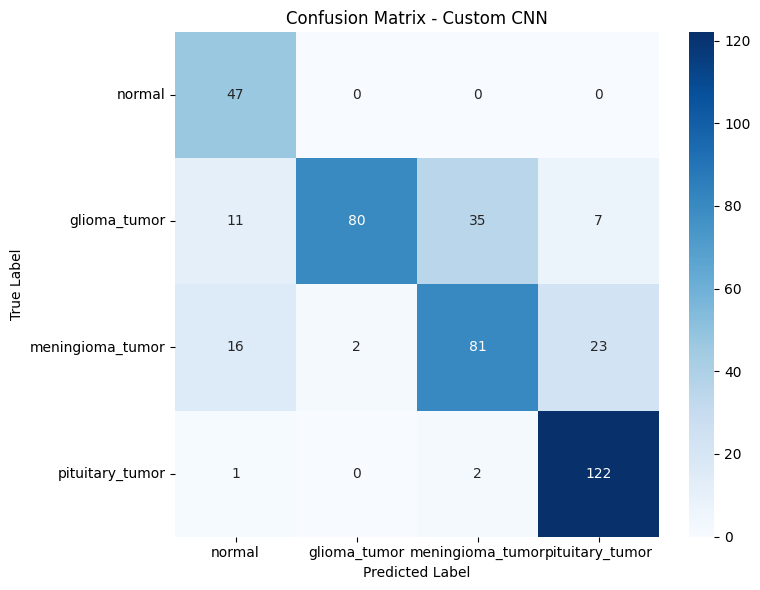

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - Custom CNN")
plt.tight_layout()
plt.show()

In [12]:
cm = confusion_matrix(all_labels, all_predictions)

print("Confusion Matrix:")
print(cm)

print("\nClass Order:")
for i, class_name in enumerate(CLASS_NAMES):
    print(f"{i}: {class_name}")

Confusion Matrix:
[[ 47   0   0   0]
 [ 11  80  35   7]
 [ 16   2  81  23]
 [  1   0   2 122]]

Class Order:
0: normal
1: glioma_tumor
2: meningioma_tumor
3: pituitary_tumor


In [13]:
import torch
import torch.nn as nn
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Get labels from training dataset
train_labels = train_loader.dataset.dataframe["class"].map(
    {name: idx for idx, name in enumerate(CLASS_NAMES)}
).values

# Calculate class weights
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(CLASS_NAMES)),
    y=train_labels
)

class_weights = torch.tensor(
    weights,
    dtype=torch.float32
).to(DEVICE)

print("Class weights:", class_weights)

Class weights: tensor([2.2938, 0.8041, 0.8717, 0.8523], device='cuda:0')


In [14]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

EPOCHS = 30
PATIENCE = 5

In [15]:
# second run 

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

best_val_loss = float("inf")
patience_counter = 0

with mlflow.start_run(run_name="Custom_CNN_Improved"):

    mlflow.log_params({
        "architecture": "BrainTumorCNN",
        "epochs": EPOCHS,
        "batch_size": BATCH_SIZE,
        "learning_rate": 0.0001,
        "optimizer": "Adam",
        "weight_decay": 1e-4,
        "class_weights": True,
        "scheduler": "ReduceLROnPlateau",
        "early_stopping_patience": PATIENCE
    })

    for epoch in range(EPOCHS):

        # Training
        model.train()
        train_loss = 0.0
        train_correct = 0
        train_total = 0

        for images, labels in train_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * images.size(0)
            train_correct += (outputs.argmax(1) == labels).sum().item()
            train_total += labels.size(0)

        train_loss /= train_total
        train_accuracy = train_correct / train_total

        # Validation
        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(DEVICE)
                labels = labels.to(DEVICE)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)
                val_correct += (outputs.argmax(1) == labels).sum().item()
                val_total += labels.size(0)

        val_loss /= val_total
        val_accuracy = val_correct / val_total

        # Scheduler
        scheduler.step(val_loss)

        current_lr = optimizer.param_groups[0]["lr"]

        # MLflow
        mlflow.log_metrics({
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
            "learning_rate": current_lr
        }, step=epoch + 1)

        print(
            f"Epoch [{epoch+1}/{EPOCHS}] "
            f"| Train Loss: {train_loss:.4f} "
            f"| Train Acc: {train_accuracy:.4f} "
            f"| Val Loss: {val_loss:.4f} "
            f"| Val Acc: {val_accuracy:.4f} "
            f"| LR: {current_lr:.6f}"
        )

        # Save best model
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            patience_counter = 0

            torch.save(
                model.state_dict(),
                MODEL_DIR / "best_cnn_improved.pth"
            )

            print("Best model saved!")

        else:
            patience_counter += 1

        # Early stopping
        if patience_counter >= PATIENCE:
            print("Early stopping triggered!")
            break


Epoch [1/30] | Train Loss: 0.5002 | Train Acc: 0.7986 | Val Loss: 0.4670 | Val Acc: 0.8033 | LR: 0.000100
Best model saved!
Epoch [2/30] | Train Loss: 0.4789 | Train Acc: 0.8147 | Val Loss: 0.4419 | Val Acc: 0.7986 | LR: 0.000100
Best model saved!
Epoch [3/30] | Train Loss: 0.4571 | Train Acc: 0.8142 | Val Loss: 0.4767 | Val Acc: 0.8056 | LR: 0.000100
Epoch [4/30] | Train Loss: 0.4498 | Train Acc: 0.8202 | Val Loss: 0.4238 | Val Acc: 0.8267 | LR: 0.000100
Best model saved!
Epoch [5/30] | Train Loss: 0.4504 | Train Acc: 0.8132 | Val Loss: 0.4534 | Val Acc: 0.8103 | LR: 0.000100
Epoch [6/30] | Train Loss: 0.4485 | Train Acc: 0.8197 | Val Loss: 0.4831 | Val Acc: 0.7939 | LR: 0.000100
Epoch [7/30] | Train Loss: 0.4417 | Train Acc: 0.8338 | Val Loss: 0.4564 | Val Acc: 0.8103 | LR: 0.000050
Epoch [8/30] | Train Loss: 0.4236 | Train Acc: 0.8247 | Val Loss: 0.4157 | Val Acc: 0.8244 | LR: 0.000050
Best model saved!
Epoch [9/30] | Train Loss: 0.4254 | Train Acc: 0.8247 | Val Loss: 0.4104 | Val A

In [16]:
best_model = BrainTumorCNN(
    num_classes=len(CLASS_NAMES)
).to(DEVICE)

best_model.load_state_dict(
    torch.load(
        MODEL_DIR / "best_cnn_improved.pth",
        map_location=DEVICE
    )
)

best_model.eval()

C:\Users\pc\AppData\Local\Temp\ipykernel_21668\2291630800.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(


BrainTumorCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=T

In [17]:
from sklearn.metrics import classification_report

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:

        images = images.to(DEVICE)

        outputs = best_model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(
    all_labels,
    all_predictions,
    target_names=CLASS_NAMES,
    digits=4
))

                  precision    recall  f1-score   support

          normal     0.7833    1.0000    0.8785        47
    glioma_tumor     0.9677    0.6767    0.7965       133
meningioma_tumor     0.7000    0.8033    0.7481       122
 pituitary_tumor     0.8955    0.9600    0.9266       125

        accuracy                         0.8314       427
       macro avg     0.8366    0.8600    0.8374       427
    weighted avg     0.8498    0.8314    0.8298       427



In [18]:
from sklearn.metrics import confusion_matrix
import pandas as pd

cm = confusion_matrix(all_labels, all_predictions)

print(pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
))

                  normal  glioma_tumor  meningioma_tumor  pituitary_tumor
normal                47             0                 0                0
glioma_tumor           3            90                38                2
meningioma_tumor       9             3                98               12
pituitary_tumor        1             0                 4              120
